<a href="https://colab.research.google.com/github/estyaprnm/Thesis/blob/main/simulasi_1_kali.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Daftar package yang dibutuhkan
packages <- c(
  "Matrix",
  "sp",
  "igraph",
  "FNN",
  "Metrics",
  "tseries"
)

# Install package yang belum tersedia
install.packages(
  packages[!(packages %in% installed.packages()[,"Package"])]
)

# Memanggil library
library(Matrix)
library(sp)
library(igraph)
library(FNN)
library(Metrics)
library(tseries)

In [ ]:
set.seed(123)

# jumlah lokasi
n <- 5

# jumlah periode waktu
T <- 120


# parameter temporal
phi0 <- diag(c(
  0.6,
  0.7,
  0.65,
  0.75,
  0.7
))


# parameter spasial
phi1 <- diag(c(
  0.25,
  0.20,
  0.30,
  0.25,
  0.20
))


# error
sigma <- 10

In [ ]:
coord <- matrix(
c(
109.3,0.0,      # Kalbar
113.9,-1.5,     # Kalteng
115.5,-3.0,     # Kalsel
116.5,0.5,      # Kaltim
116.0,3.0       # Kaltara
),
ncol=2,
byrow=TRUE
)

rownames(coord)<-
c(
"Kalimantan Barat",
"Kalimantan Tengah",
"Kalimantan Selatan",
"Kalimantan Timur",
"Kalimantan Utara"
)

coord

Kalimantan Barat,109.3,0.0
Kalimantan Tengah,113.9,-1.5
Kalimantan Selatan,115.5,-3.0
Kalimantan Timur,116.5,0.5
Kalimantan Utara,116.0,3.0


#matriks pembobot

##uniform

In [ ]:
W_uniform <- matrix(1,n,n)

diag(W_uniform)<-0


W_uniform <-
W_uniform/rowSums(W_uniform)


W_uniform

0.00,0.25,0.25,0.25,0.25
0.25,0.00,0.25,0.25,0.25
0.25,0.25,0.00,0.25,0.25
0.25,0.25,0.25,0.00,0.25
0.25,0.25,0.25,0.25,0.00


In [ ]:
W_queen <- matrix(
c(
0,1,0,0,0,
1,0,1,0,0,
0,1,0,1,0,
0,0,1,0,1,
0,0,0,1,0
),
5,
5,
byrow=TRUE
)


W_queen <-
W_queen/rowSums(W_queen)


W_queen

0.0,1.0,0.0,0.0,0.0
0.5,0.0,0.5,0.0,0.0
0.0,0.5,0.0,0.5,0.0
0.0,0.0,0.5,0.0,0.5
0.0,0.0,0.0,1.0,0.0


In [ ]:
dist_matrix <-
as.matrix(dist(coord))


W_IDW <- 1/dist_matrix


diag(W_IDW)<-0


W_IDW <-
W_IDW/rowSums(W_IDW)


W_IDW

,Kalimantan Barat,Kalimantan Tengah,Kalimantan Selatan,Kalimantan Timur,Kalimantan Utara
Kalimantan Barat,0.0000000,0.3298210,0.2316897,0.2211067,0.2173827
Kalimantan Tengah,0.1768206,0.0000000,0.3900866,0.2608119,0.1722809
Kalimantan Selatan,0.1393403,0.4375992,0.0000000,0.2636581,0.1594025
Kalimantan Timur,0.1247836,0.2745545,0.2474154,0.0000000,0.3532466
Kalimantan Utara,0.1520468,0.2247682,0.1853862,0.4377989,0.0000000


In [ ]:
W_NCC <- matrix(0,n,n)


for(i in 1:n){

for(j in 1:n){

if(i!=j){

W_NCC[i,j] <-
abs(cor(
rnorm(T),
rnorm(T)
))

}

}

}


W_NCC <-
W_NCC/rowSums(W_NCC)


W_NCC

0.00000000,0.22447899,0.10463880,0.1886936,0.4821886
0.06477331,0.00000000,0.09427197,0.3014995,0.5394552
0.32042210,0.09789973,0.00000000,0.1295583,0.4521199
0.07359828,0.39636730,0.34706522,0.0000000,0.1829692
0.18144136,0.46254860,0.18172858,0.1742815,0.0000000


,Kalimantan Barat,Kalimantan Tengah,Kalimantan Selatan,Kalimantan Timur,Kalimantan Utara
Kalimantan Barat,0.0000000,1.0,0.0000000,0.0000000,0.0
Kalimantan Tengah,0.3333333,0.0,0.3333333,0.3333333,0.0
Kalimantan Selatan,0.0000000,1.0,0.0000000,0.0000000,0.0
Kalimantan Timur,0.0000000,0.5,0.0000000,0.0000000,0.5
Kalimantan Utara,0.0000000,0.0,0.0000000,1.0000000,0.0


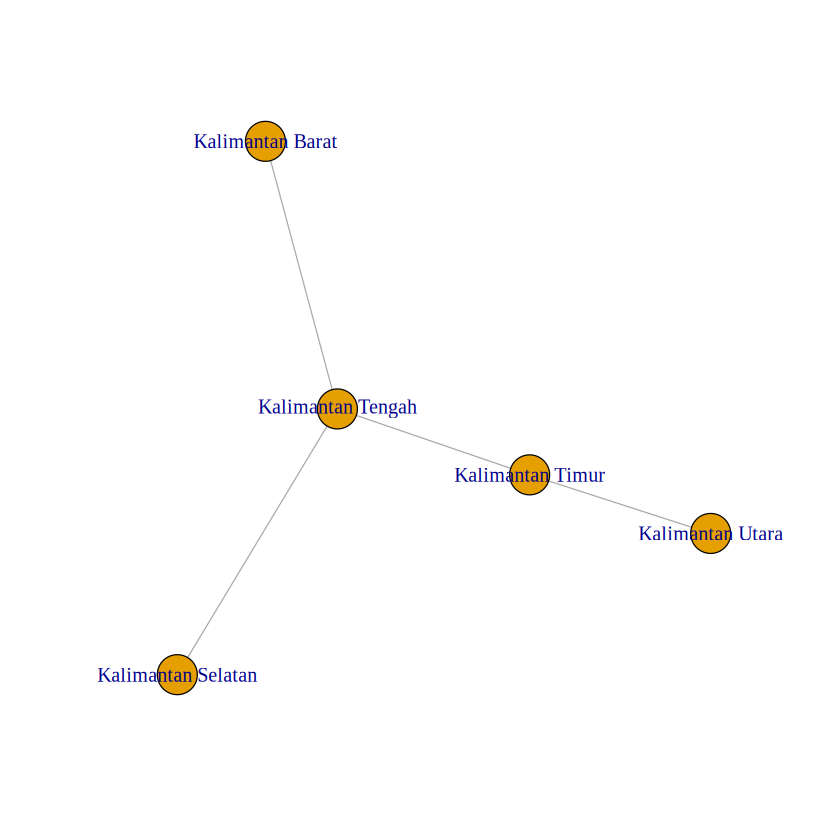

In [ ]:
distance_graph <-
graph_from_adjacency_matrix(
dist_matrix,
weighted=TRUE,
mode="undirected"
)


mst <-
mst(distance_graph)


plot(mst)


W_MST <-
as.matrix(as_adjacency_matrix(mst))


diag(W_MST)<-0


W_MST <-
W_MST/rowSums(W_MST)


W_MST

#membangkitkan data hotspot

In [ ]:
W <- W_MST


Z <- matrix(0,T,n)


Z[1,] <- abs(rnorm(n,100,20))


for(t in 2:T){

error <- rnorm(n,0,sigma)


Z[t,] <-
phi0%*%Z[t-1,] +
phi1%*%(W%*%Z[t-1,])+
error

}


colnames(Z)<-
c(
"Kalbar",
"Kalteng",
"Kalsel",
"Kaltim",
"Kaltara"
)


head(Z)

Kalbar,Kalteng,Kalsel,Kaltim,Kaltara
73.36126,105.21800,143.81350,95.52899,88.83544
84.06985,102.84432,139.22675,101.82745,85.38731
83.04155,85.10704,124.04193,104.30266,98.80262
79.67301,96.70083,106.74620,92.80284,81.88081
59.08909,68.34299,94.62374,87.11634,90.04890
36.27726,65.48494,77.72865,91.70884,88.18686


#membandingkan 5 matriks pembobot

In [ ]:
weights <- list(
Uniform=W_uniform,
Queen=W_queen,
IDW=W_IDW,
NCC=W_NCC,
MST=W_MST
)

#forecasting

In [ ]:
forecast_GSTAR <- function(Z,W){

pred <- matrix(0,nrow=nrow(Z)-1,ncol=ncol(Z))


for(t in 2:nrow(Z)){


pred[t-1,] <-
phi0%*%Z[t-1,]+
phi1%*%(W%*%Z[t-1,])


}

return(pred)

}

#evaluasi matriks pembobot

In [ ]:
hasil <- data.frame()


for(i in names(weights)){


pred <-
forecast_GSTAR(
Z,
weights[[i]]
)


rmse_value <-
rmse(
Z[-1,],
pred
)


hasil <-
rbind(
hasil,
data.frame(
Matriks=i,
RMSE=rmse_value
)
)

}


hasil

Matriks,RMSE
<chr>,<dbl>
Uniform,10.45665
Queen,10.39142
IDW,10.38424
NCC,10.62828
MST,10.19477
